General Evaluation Function for Multiple Models & Datasets

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import torch
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from tqdm import tqdm

In [14]:
def evaluate_models(models, model_names, data_loaders, dataset_names, device='cuda'):
    """
    General evaluation function for multiple models across multiple datasets.


    Args:
    models (list): list of PyTorch models.
    model_names (list): list of model names (strings).
    data_loaders (list): list of DataLoader objects for datasets.
    dataset_names (list): list of dataset names (strings).
    device (str): device to run evaluation ('cuda' or 'cpu').


    Returns:
    results_dict (dict): nested dictionary containing metrics for each model/dataset.
    """
    results_dict = {}


    for model, m_name in zip(models, model_names):
        model.to(device)
        model.eval()
        results_dict[m_name] = {}


        for loader, d_name in zip(data_loaders, dataset_names):
            y_true, y_pred, y_prob = [], [], []


            with torch.no_grad():
                for images, labels in tqdm(loader):
                    images, labels = images.to(device), labels.to(device)
                    outputs = model(images)
                    probs = torch.softmax(outputs.logits, dim=1)[:, 1]
                    preds = torch.argmax(outputs.logits, dim=1)
                    y_true.extend(labels.cpu().numpy())
                    y_pred.extend(preds.cpu().numpy())
                    y_prob.extend(probs.cpu().numpy())


            # Compute metrics
            acc = accuracy_score(y_true, y_pred)
            prec = precision_score(y_true, y_pred)
            rec = recall_score(y_true, y_pred)
            f1 = f1_score(y_true, y_pred)
            auc = roc_auc_score(y_true, y_prob)
            cm = confusion_matrix(y_true, y_pred)


            # Store results
            results_dict[m_name][d_name] = {
            'accuracy': acc,
            'precision': prec,
            'recall': rec,
            'f1': f1,
            'roc_auc': auc,
            'confusion_matrix': cm
            }


            # --- Plot confusion matrix ---
            plt.figure(figsize=(5,4))
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Real','AI'], yticklabels=['Real','AI'])
            plt.title(f'Confusion Matrix: {m_name} on {d_name}')
            plt.xlabel('Predicted')
            plt.ylabel('True')
            plt.show()


            # --- ROC Curve ---
            from sklearn.metrics import roc_curve
            fpr, tpr, _ = roc_curve(y_true, y_prob)
            plt.figure()
            plt.plot(fpr, tpr, label=f'{m_name} on {d_name} (AUC={auc:.2f})')
            plt.plot([0,1],[0,1],'--', color='gray')
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.title('ROC Curve')
            plt.legend()
            plt.show()


            # --- Classification report ---
            print(f'Classification Report for {m_name} on {d_name}:')
            print(classification_report(y_true, y_pred, target_names=['Real','AI']))


    return results_dict

In [3]:
class ImageCSVLoader(Dataset):
    def __init__(self, dataframe, processor):
        self.dataframe = dataframe.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image = Image.open(row['path']).convert('RGB')
        label = int(row['label'])

        processed = self.processor(images=image, return_tensors="pt")
        pixel_values = processed['pixel_values'].squeeze(0)
        return pixel_values, label

In [4]:
df = pd.read_csv("../data/classifier_results.csv")

In [17]:
from transformers import AutoImageProcessor, AutoModelForImageClassification

processor = AutoImageProcessor.from_pretrained("prithivMLmods/deepfake-detector-model-v1", use_fast=True)
model = AutoModelForImageClassification.from_pretrained("prithivMLmods/deepfake-detector-model-v1")
model.eval()

# create dataloaders for each category
groups = df.groupby('top1_name')

dataloaders = []
names = []
for category, category_df in groups:
    dataset = ImageCSVLoader(category_df, processor)
    loader = DataLoader(dataset, batch_size=32, shuffle=False)
    dataloaders.append(loader)
    names.append(category)

100%|██████████| 1/1 [00:00<00:00,  3.99it/s]


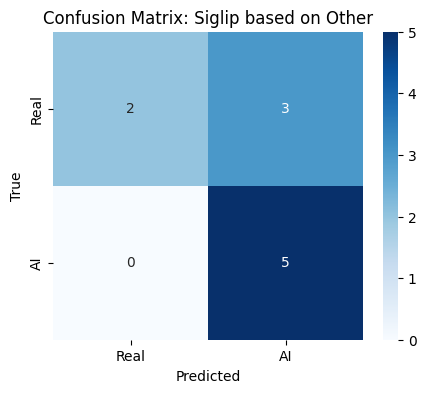

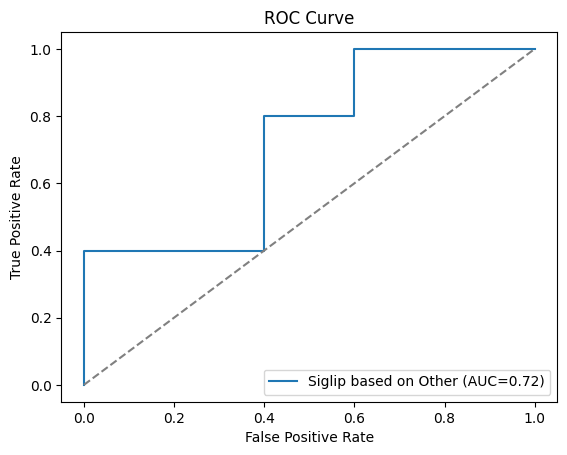

Classification Report for Siglip based on Other:
              precision    recall  f1-score   support

        Real       1.00      0.40      0.57         5
          AI       0.62      1.00      0.77         5

    accuracy                           0.70        10
   macro avg       0.81      0.70      0.67        10
weighted avg       0.81      0.70      0.67        10



100%|██████████| 386/386 [02:58<00:00,  2.16it/s]


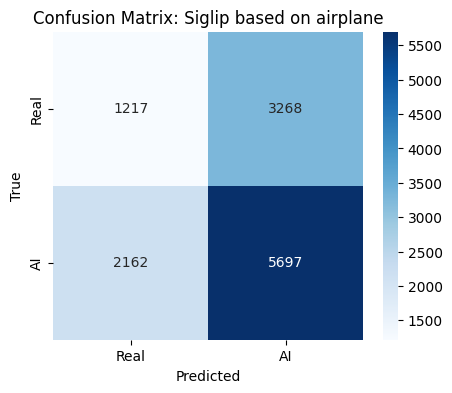

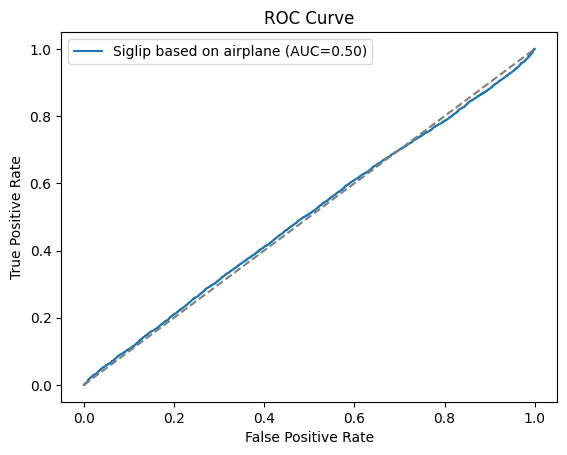

Classification Report for Siglip based on airplane:
              precision    recall  f1-score   support

        Real       0.36      0.27      0.31      4485
          AI       0.64      0.72      0.68      7859

    accuracy                           0.56     12344
   macro avg       0.50      0.50      0.49     12344
weighted avg       0.54      0.56      0.54     12344



100%|██████████| 291/291 [02:15<00:00,  2.14it/s]


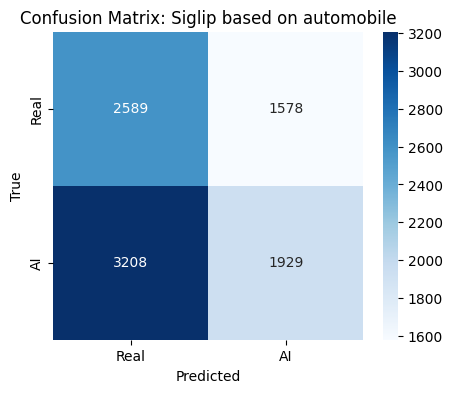

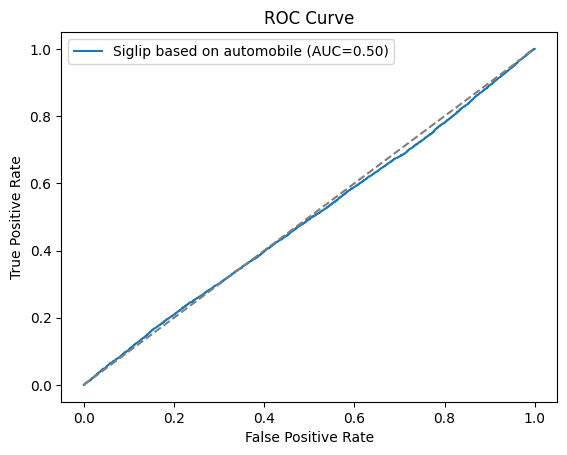

Classification Report for Siglip based on automobile:
              precision    recall  f1-score   support

        Real       0.45      0.62      0.52      4167
          AI       0.55      0.38      0.45      5137

    accuracy                           0.49      9304
   macro avg       0.50      0.50      0.48      9304
weighted avg       0.50      0.49      0.48      9304



100%|██████████| 263/263 [01:59<00:00,  2.20it/s]


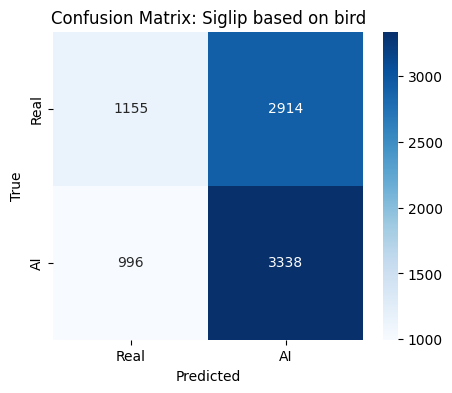

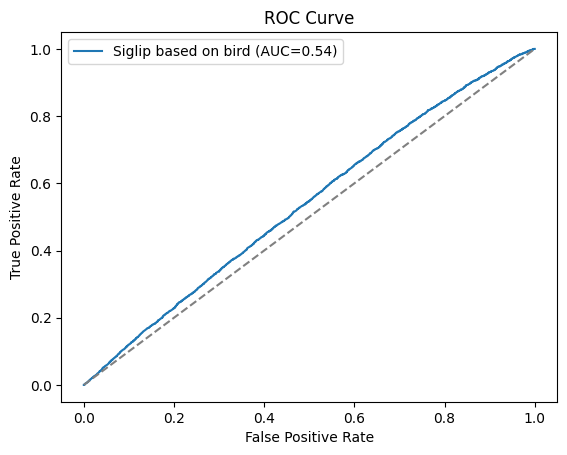

Classification Report for Siglip based on bird:
              precision    recall  f1-score   support

        Real       0.54      0.28      0.37      4069
          AI       0.53      0.77      0.63      4334

    accuracy                           0.53      8403
   macro avg       0.54      0.53      0.50      8403
weighted avg       0.54      0.53      0.51      8403



100%|██████████| 398/398 [01:31<00:00,  4.35it/s]


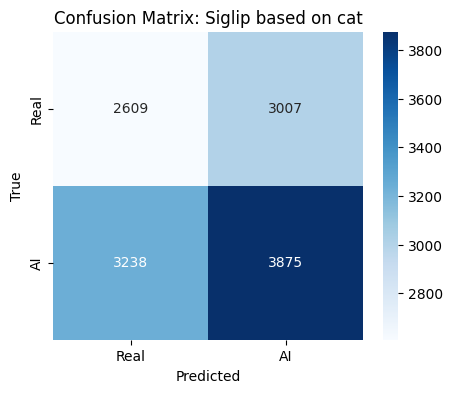

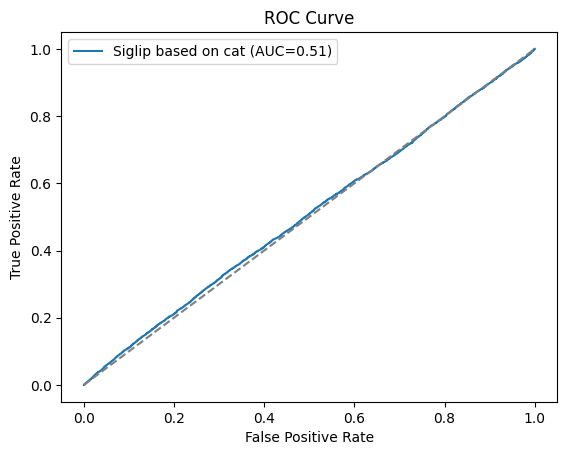

Classification Report for Siglip based on cat:
              precision    recall  f1-score   support

        Real       0.45      0.46      0.46      5616
          AI       0.56      0.54      0.55      7113

    accuracy                           0.51     12729
   macro avg       0.50      0.50      0.50     12729
weighted avg       0.51      0.51      0.51     12729



100%|██████████| 437/437 [01:38<00:00,  4.43it/s]


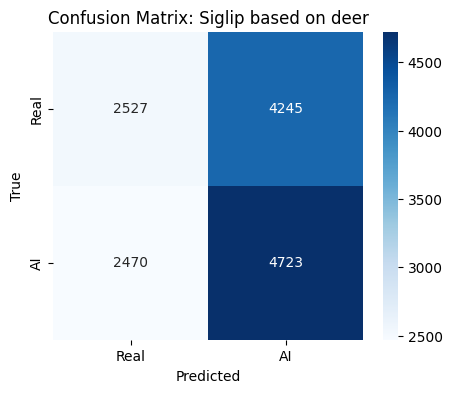

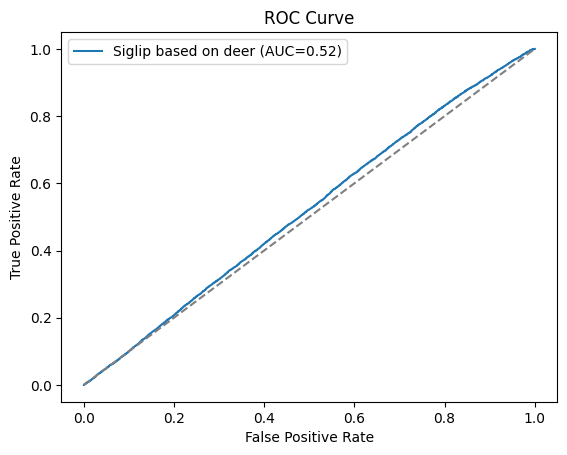

Classification Report for Siglip based on deer:
              precision    recall  f1-score   support

        Real       0.51      0.37      0.43      6772
          AI       0.53      0.66      0.58      7193

    accuracy                           0.52     13965
   macro avg       0.52      0.51      0.51     13965
weighted avg       0.52      0.52      0.51     13965



100%|██████████| 287/287 [01:08<00:00,  4.17it/s]


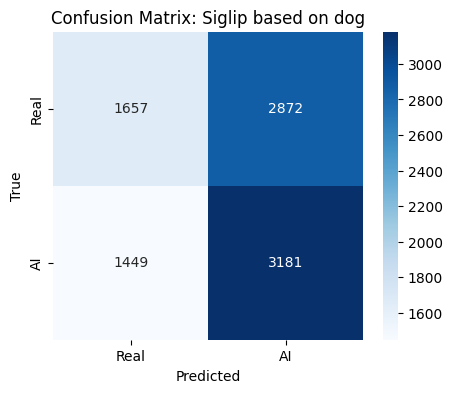

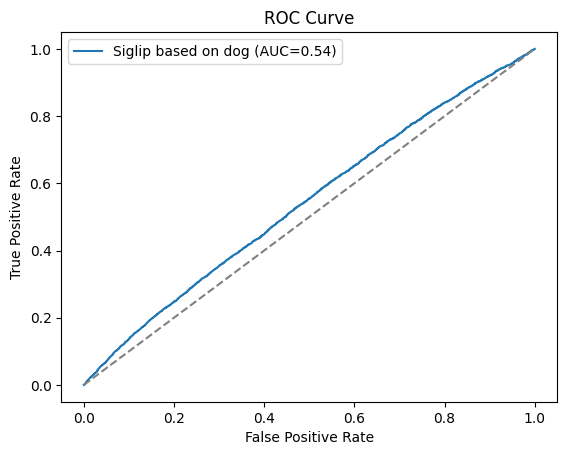

Classification Report for Siglip based on dog:
              precision    recall  f1-score   support

        Real       0.53      0.37      0.43      4529
          AI       0.53      0.69      0.60      4630

    accuracy                           0.53      9159
   macro avg       0.53      0.53      0.51      9159
weighted avg       0.53      0.53      0.52      9159



100%|██████████| 343/343 [01:21<00:00,  4.20it/s]


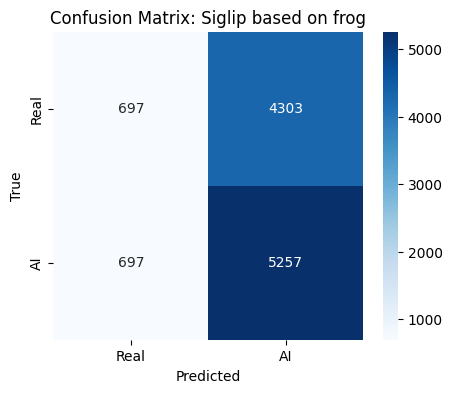

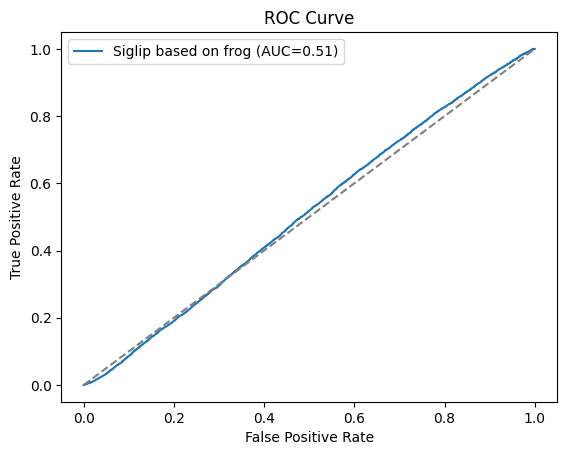

Classification Report for Siglip based on frog:
              precision    recall  f1-score   support

        Real       0.50      0.14      0.22      5000
          AI       0.55      0.88      0.68      5954

    accuracy                           0.54     10954
   macro avg       0.52      0.51      0.45     10954
weighted avg       0.53      0.54      0.47     10954



100%|██████████| 309/309 [01:12<00:00,  4.27it/s]


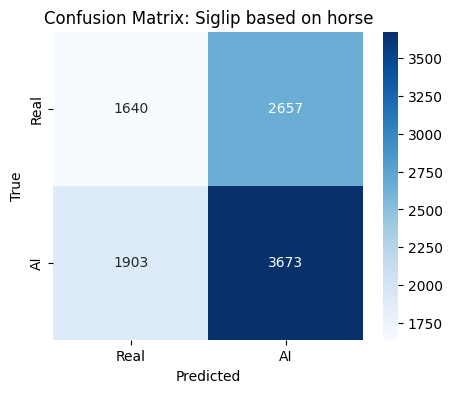

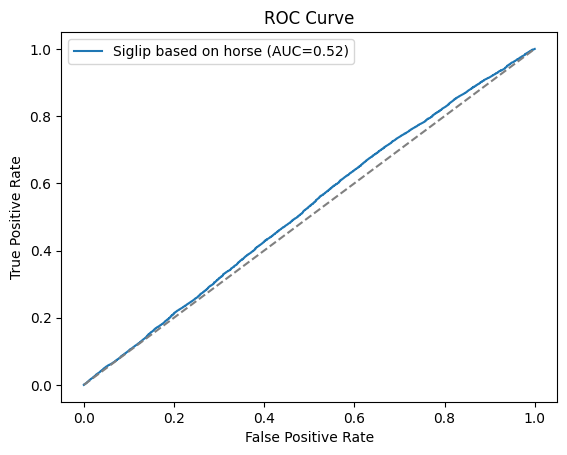

Classification Report for Siglip based on horse:
              precision    recall  f1-score   support

        Real       0.46      0.38      0.42      4297
          AI       0.58      0.66      0.62      5576

    accuracy                           0.54      9873
   macro avg       0.52      0.52      0.52      9873
weighted avg       0.53      0.54      0.53      9873



100%|██████████| 401/401 [01:35<00:00,  4.20it/s]


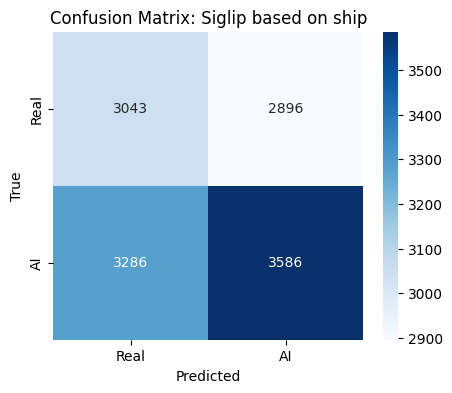

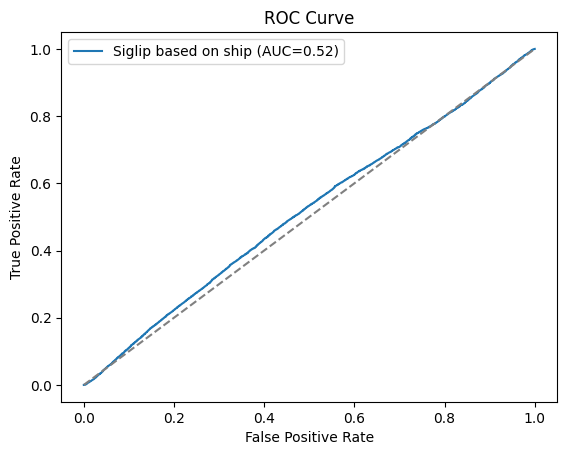

Classification Report for Siglip based on ship:
              precision    recall  f1-score   support

        Real       0.48      0.51      0.50      5939
          AI       0.55      0.52      0.54      6872

    accuracy                           0.52     12811
   macro avg       0.52      0.52      0.52     12811
weighted avg       0.52      0.52      0.52     12811



100%|██████████| 327/327 [01:16<00:00,  4.29it/s]


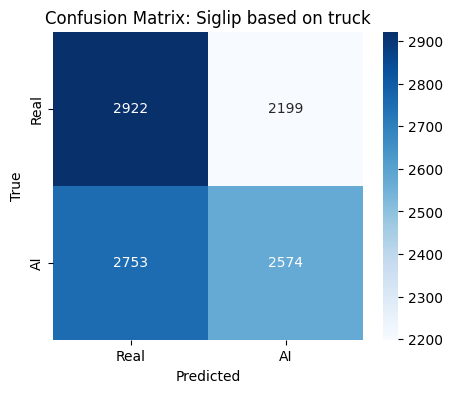

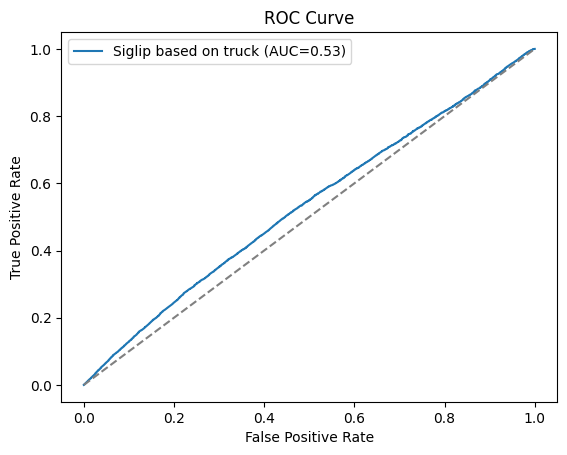

Classification Report for Siglip based on truck:
              precision    recall  f1-score   support

        Real       0.51      0.57      0.54      5121
          AI       0.54      0.48      0.51      5327

    accuracy                           0.53     10448
   macro avg       0.53      0.53      0.53     10448
weighted avg       0.53      0.53      0.53     10448



In [18]:

models = [model]
model_names = ["Siglip based"]
results = evaluate_models(models, model_names, dataloaders, names)

In [21]:
from transformers import AutoImageProcessor, AutoModelForImageClassification

processor = AutoImageProcessor.from_pretrained("prithivMLmods/Deep-Fake-Detector-v2-Model", use_fast=True)
model = AutoModelForImageClassification.from_pretrained("prithivMLmods/Deep-Fake-Detector-v2-Model")
model.eval()

# create dataloaders for each category
groups = df.groupby('top1_name')

dataloaders = []
names = []
for category, category_df in groups:
    dataset = ImageCSVLoader(category_df, processor)
    loader = DataLoader(dataset, batch_size=32, shuffle=False)
    dataloaders.append(loader)
    names.append(category)

100%|██████████| 1/1 [00:00<00:00,  6.31it/s]


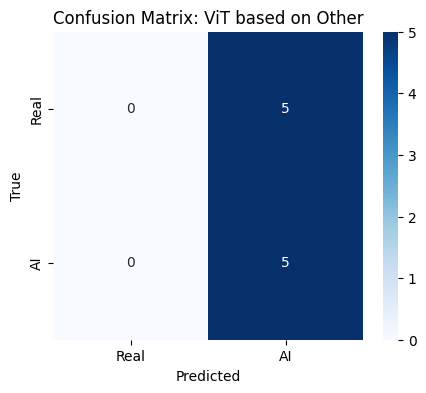

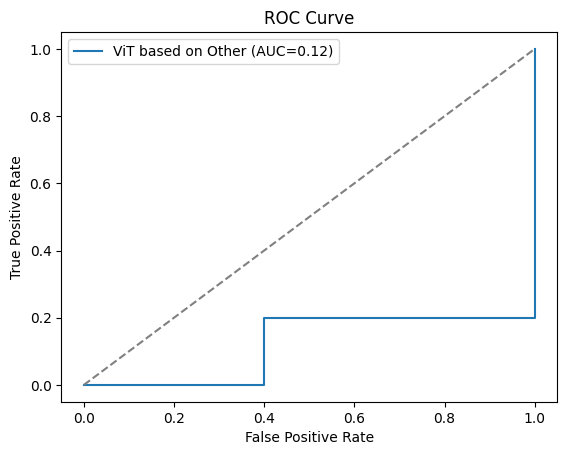

/home/user/PML_Project/ai-image-detector-comparison/pml/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/user/PML_Project/ai-image-detector-comparison/pml/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/user/PML_Project/ai-image-detector-comparison/pml/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to co

Classification Report for ViT based on Other:
              precision    recall  f1-score   support

        Real       0.00      0.00      0.00         5
          AI       0.50      1.00      0.67         5

    accuracy                           0.50        10
   macro avg       0.25      0.50      0.33        10
weighted avg       0.25      0.50      0.33        10



100%|██████████| 386/386 [01:46<00:00,  3.63it/s]


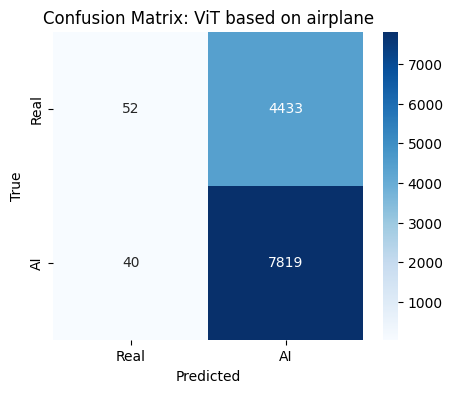

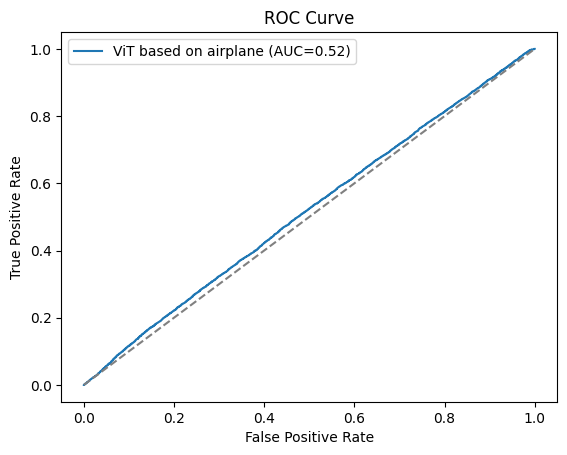

Classification Report for ViT based on airplane:
              precision    recall  f1-score   support

        Real       0.57      0.01      0.02      4485
          AI       0.64      0.99      0.78      7859

    accuracy                           0.64     12344
   macro avg       0.60      0.50      0.40     12344
weighted avg       0.61      0.64      0.50     12344



100%|██████████| 291/291 [01:04<00:00,  4.54it/s]


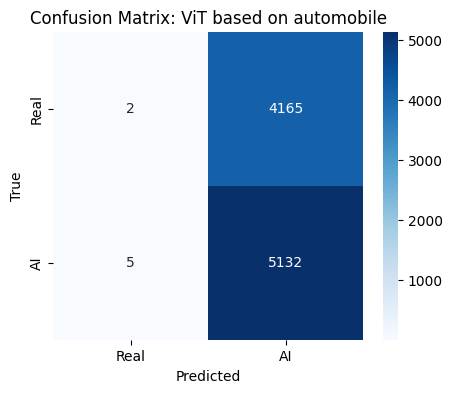

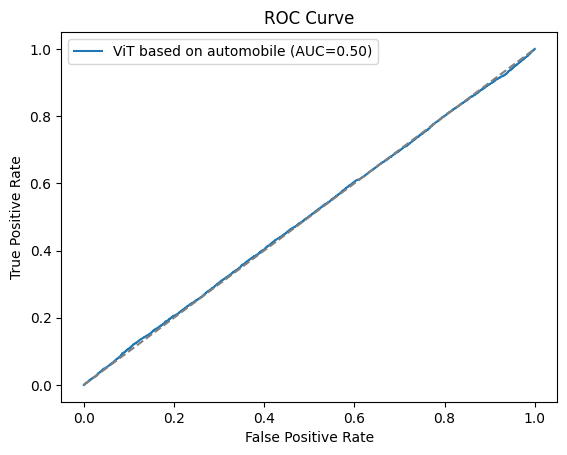

Classification Report for ViT based on automobile:
              precision    recall  f1-score   support

        Real       0.29      0.00      0.00      4167
          AI       0.55      1.00      0.71      5137

    accuracy                           0.55      9304
   macro avg       0.42      0.50      0.36      9304
weighted avg       0.43      0.55      0.39      9304



100%|██████████| 263/263 [00:58<00:00,  4.48it/s]


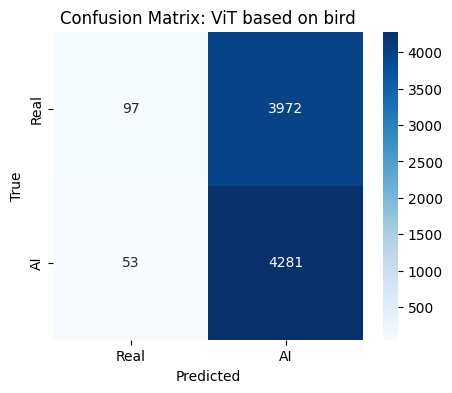

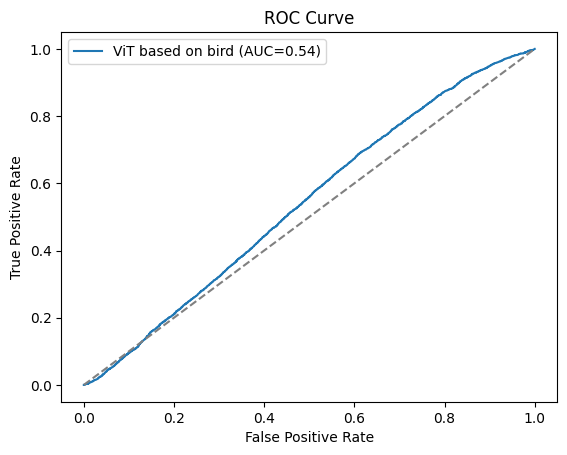

Classification Report for ViT based on bird:
              precision    recall  f1-score   support

        Real       0.65      0.02      0.05      4069
          AI       0.52      0.99      0.68      4334

    accuracy                           0.52      8403
   macro avg       0.58      0.51      0.36      8403
weighted avg       0.58      0.52      0.37      8403



100%|██████████| 398/398 [01:25<00:00,  4.63it/s]


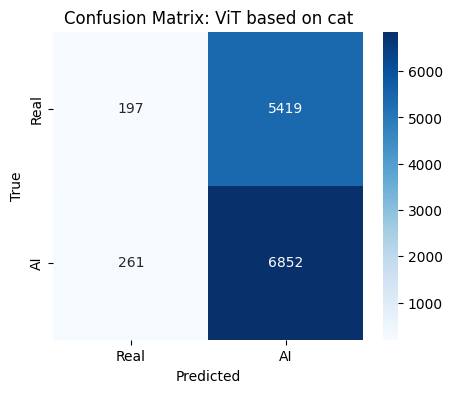

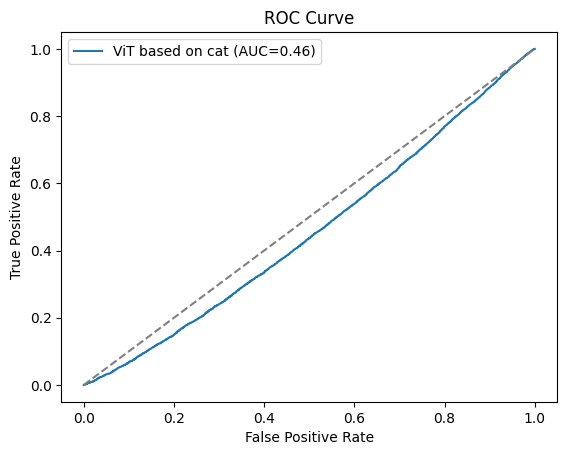

Classification Report for ViT based on cat:
              precision    recall  f1-score   support

        Real       0.43      0.04      0.06      5616
          AI       0.56      0.96      0.71      7113

    accuracy                           0.55     12729
   macro avg       0.49      0.50      0.39     12729
weighted avg       0.50      0.55      0.42     12729



100%|██████████| 437/437 [01:36<00:00,  4.52it/s]


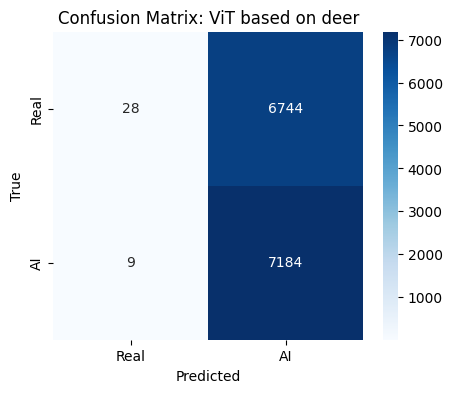

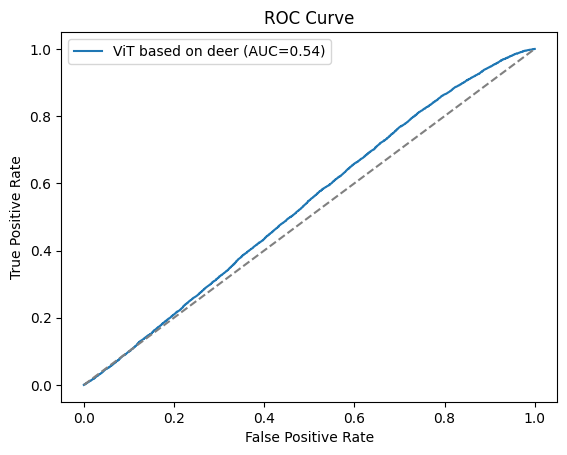

Classification Report for ViT based on deer:
              precision    recall  f1-score   support

        Real       0.76      0.00      0.01      6772
          AI       0.52      1.00      0.68      7193

    accuracy                           0.52     13965
   macro avg       0.64      0.50      0.34     13965
weighted avg       0.63      0.52      0.35     13965



100%|██████████| 287/287 [01:00<00:00,  4.74it/s]


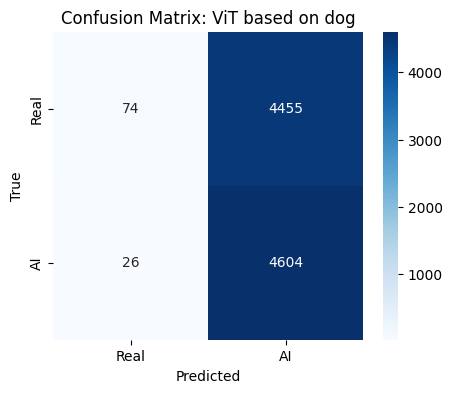

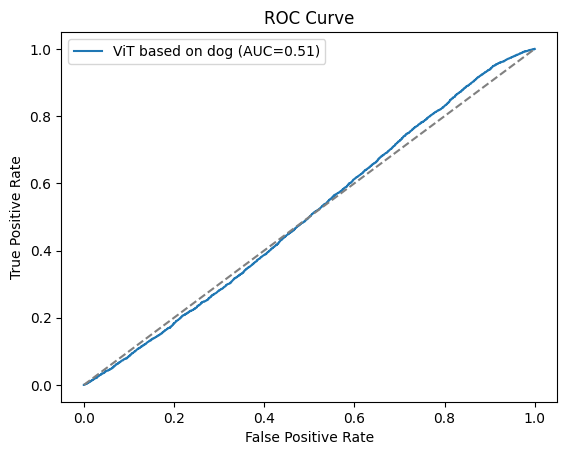

Classification Report for ViT based on dog:
              precision    recall  f1-score   support

        Real       0.74      0.02      0.03      4529
          AI       0.51      0.99      0.67      4630

    accuracy                           0.51      9159
   macro avg       0.62      0.51      0.35      9159
weighted avg       0.62      0.51      0.36      9159



100%|██████████| 343/343 [01:17<00:00,  4.42it/s]


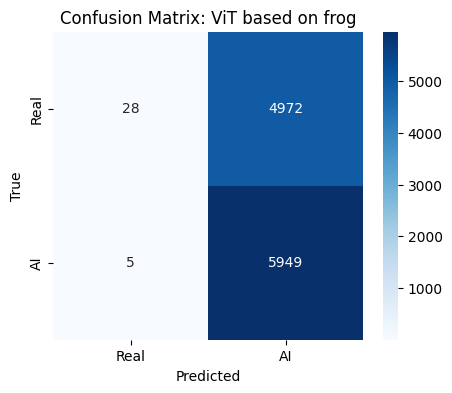

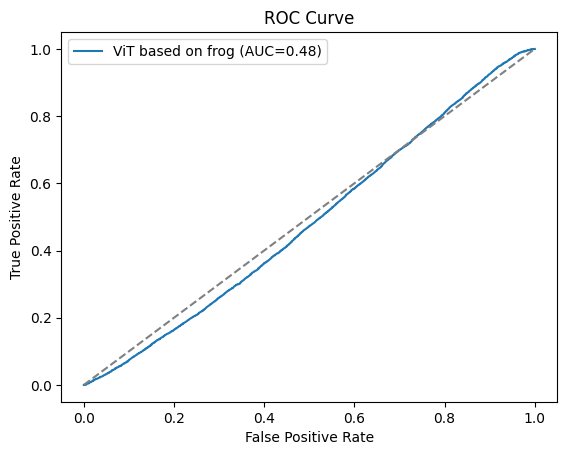

Classification Report for ViT based on frog:
              precision    recall  f1-score   support

        Real       0.85      0.01      0.01      5000
          AI       0.54      1.00      0.71      5954

    accuracy                           0.55     10954
   macro avg       0.70      0.50      0.36     10954
weighted avg       0.68      0.55      0.39     10954



100%|██████████| 309/309 [01:08<00:00,  4.54it/s]


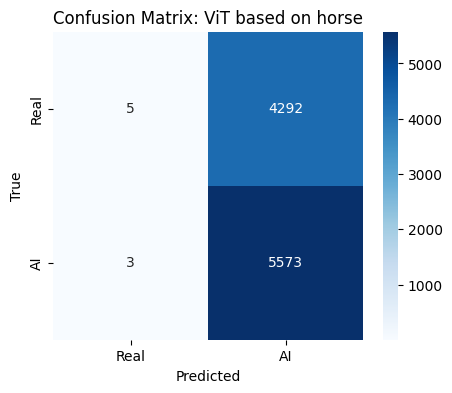

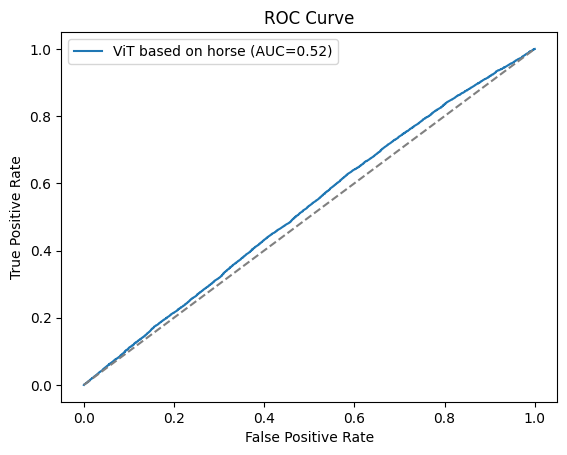

Classification Report for ViT based on horse:
              precision    recall  f1-score   support

        Real       0.62      0.00      0.00      4297
          AI       0.56      1.00      0.72      5576

    accuracy                           0.56      9873
   macro avg       0.59      0.50      0.36      9873
weighted avg       0.59      0.56      0.41      9873



100%|██████████| 401/401 [01:26<00:00,  4.64it/s]


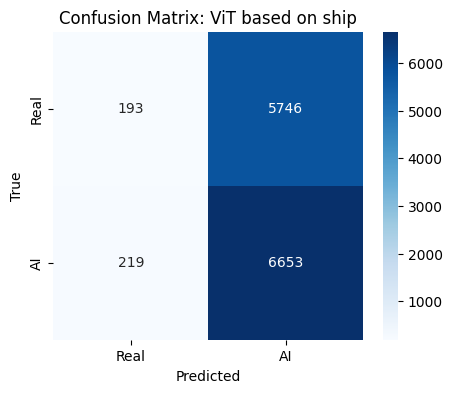

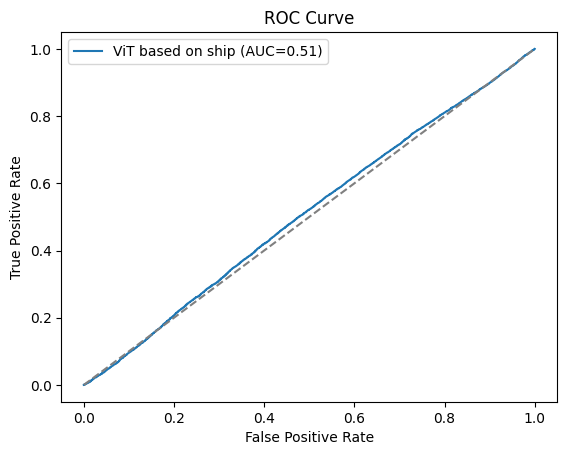

Classification Report for ViT based on ship:
              precision    recall  f1-score   support

        Real       0.47      0.03      0.06      5939
          AI       0.54      0.97      0.69      6872

    accuracy                           0.53     12811
   macro avg       0.50      0.50      0.38     12811
weighted avg       0.50      0.53      0.40     12811



100%|██████████| 327/327 [01:11<00:00,  4.56it/s]


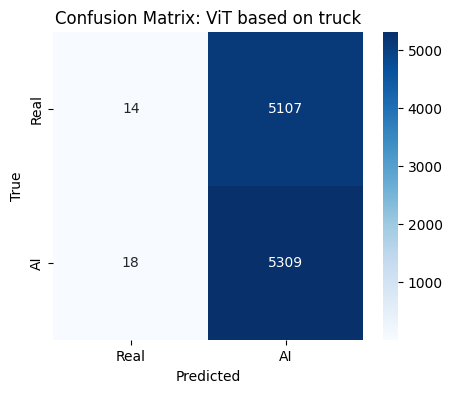

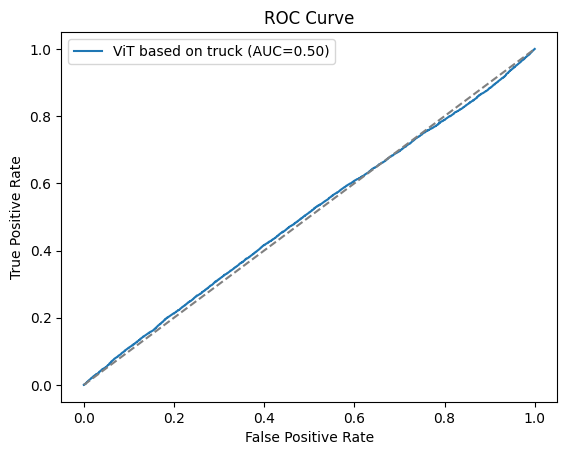

Classification Report for ViT based on truck:
              precision    recall  f1-score   support

        Real       0.44      0.00      0.01      5121
          AI       0.51      1.00      0.67      5327

    accuracy                           0.51     10448
   macro avg       0.47      0.50      0.34     10448
weighted avg       0.47      0.51      0.35     10448



In [22]:

models = [model]
model_names = ["ViT based"]
results = evaluate_models(models, model_names, dataloaders, names)